# Recurrent Neural Networks for Time-Series Forecasting: An Empirical Reimplementation and Enhancement of LSTM, GRU, and Vanilla RNNs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alebuenoaz/LSTM-and-GRU-Time-Series-Forecasting/blob/main/RNN_multi.ipynb)

**Project Title:** Reimplementation and Enhancement of LSTM and GRU Networks for Time-Series Forecasting  
**Course / Discipline:** Deep Learning for Sequential Data & Time-Series Modeling  
**Base Research Paper:** *"An Open-Source and Reproducible Implementation of GRU and LSTM Networks for Time Series Forecasting"*  
**Authors:** Gissel Velarde, Pedro Brañez, Alejandro Bueno, Rodrigo Heredia, and Mateo Lopez (ITISE 2022)

---

### Abstract
This project presents an independent, research-oriented reimplementation and architectural enhancement of recurrent neural networks for multi-step and single-step time-series forecasting. While the original research evaluated LSTM and GRU networks on the Indian banking stock index (**BANKEX**) and synthetic cyclical activity signals, this implementation builds an end-to-end modular PyTorch pipeline with strict leakage-free chronological data partitioning, introduces the foundational **Vanilla (Elman) RNN** as a baseline, and executes five controlled empirical experiments:
1. **Architectural Benchmark:** Vanilla RNN vs. LSTM vs. GRU vs. Persistence Baseline.
2. **Receptive Field Analysis:** Sequence lookback lengths ($w \in \{7, 14, 30\}$ days).
3. **Capacity Scaling:** Hidden state dimensionality ($H \in \{32, 64, 128\}$ units).
4. **Regularization Study:** Dropout rates ($p \in \{0.0, 0.2, 0.4\}$).
5. **Efficiency Analysis:** Train time, parameter footprint, and per-sample inference latency.


## 1. Environment Setup & Data Acquisition

This notebook is configured to run smoothly in Google Colab (CPU or GPU) and local environments. In the cell below, we check dependencies, set global deterministic random seeds, and ensure the raw datasets (`BANKEX.csv` and `activities.csv`) are accessible.


In [1]:
# Standard library and core scientific stack
import os
import sys
import math
import time
import copy
import random
from pathlib import Path
from typing import Dict, List, Tuple, Union, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Global reproducibility
def set_seed(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu'))
print(f"PyTorch Version: {torch.__version__} | Target Execution Device: {device}")

# Ensure data directories exist
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR = Path("results/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Download or verify BANKEX.csv and activities.csv
bankex_path = DATA_DIR / "BANKEX.csv"
activities_path = DATA_DIR / "activities.csv"

# If running directly inside a fresh Google Colab instance without repo clone:
if not bankex_path.is_file() or not activities_path.is_file():
    print("Fetching reference datasets from GitHub repository...")
    import urllib.request
    base_url = "https://raw.githubusercontent.com/Alebuenoaz/LSTM-and-GRU-Time-Series-Forecasting/main/"
    if not bankex_path.is_file():
        urllib.request.urlretrieve(base_url + "BANKEX.csv", bankex_path)
    if not activities_path.is_file():
        urllib.request.urlretrieve(base_url + "activities.csv", activities_path)

print(f"BANKEX dataset verified at: {bankex_path} ({bankex_path.stat().st_size / 1024:.1f} KB)")
print(f"Activities dataset verified at: {activities_path} ({activities_path.stat().st_size / 1024:.1f} KB)")


PyTorch Version: 2.8.0 | Target Execution Device: cpu
BANKEX dataset verified at: data/raw/BANKEX.csv (740.2 KB)
Activities dataset verified at: data/raw/activities.csv (875.0 KB)


## 2. Exploratory Data Analysis (EDA)

The benchmark involves two distinct sequential datasets:
1. **BANKEX.csv**: Daily historical closing stock prices for 10 major commercial banking institutions in India across 3,032 trading days (2005–2017). Characterized by non-stationarity, economic regime shifts, and stochastic volatility.
2. **activities.csv**: 10 synthetic signals across 3,584 time points modeling human weekly cyclical activity (5 days high activity, 2 days low activity) with linear trend drifts and uniform stochastic noise.


BANKEX Shape: (10, 3032) | Missing NaNs: 0
  Range: [8.29, 1790.65] | Mean: 212.66 | Std: 219.05
Activities Shape: (10, 3584) | Missing NaNs: 0
  Range: [0.00, 14.22] | Mean: 4.48 | Std: 3.67


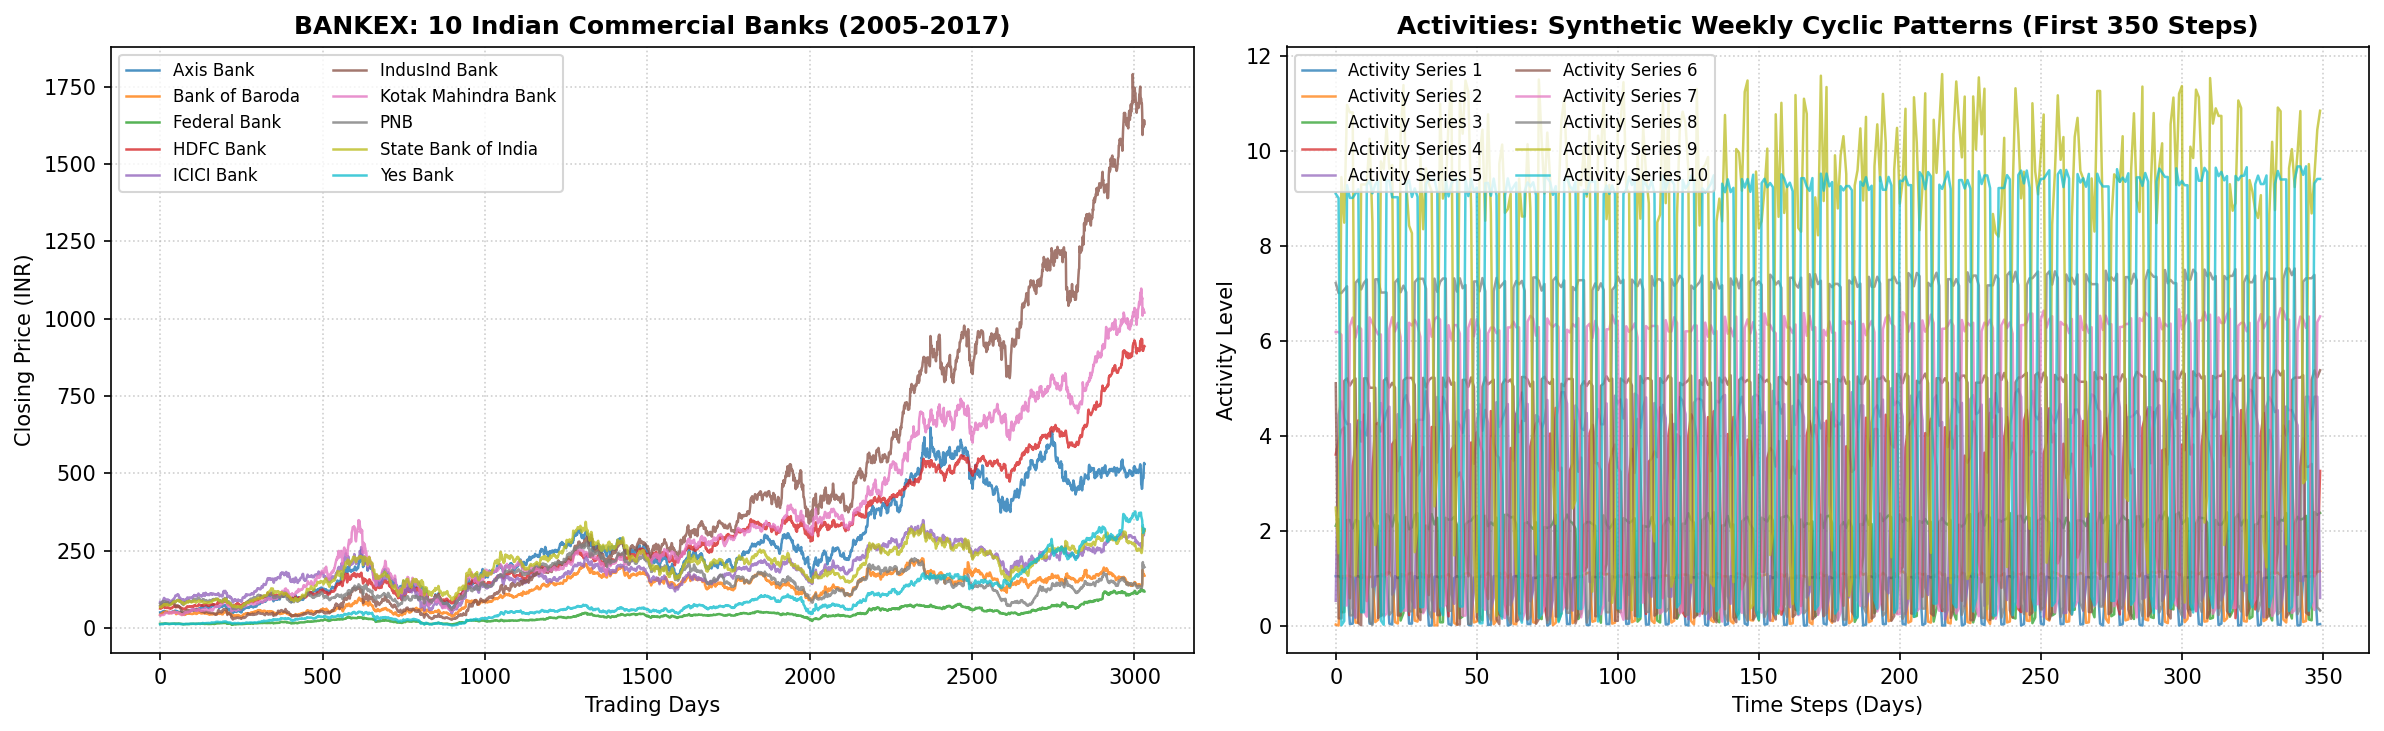

In [2]:
# Load CSVs as clean NumPy arrays
bankex_raw = pd.read_csv(bankex_path, header=None).to_numpy(dtype=np.float32)
activities_raw = pd.read_csv(activities_path, header=None).to_numpy(dtype=np.float32)

print(f"BANKEX Shape: {bankex_raw.shape} | Missing NaNs: {np.isnan(bankex_raw).sum()}")
print(f"  Range: [{np.nanmin(bankex_raw):.2f}, {np.nanmax(bankex_raw):.2f}] | Mean: {np.nanmean(bankex_raw):.2f} | Std: {np.nanstd(bankex_raw):.2f}")

print(f"Activities Shape: {activities_raw.shape} | Missing NaNs: {np.isnan(activities_raw).sum()}")
print(f"  Range: [{np.nanmin(activities_raw):.2f}, {np.nanmax(activities_raw):.2f}] | Mean: {np.nanmean(activities_raw):.2f} | Std: {np.nanstd(activities_raw):.2f}")

# Bank constituent tickers
BANK_NAMES = [
    "Axis Bank", "Bank of Baroda", "Federal Bank", "HDFC Bank", "ICICI Bank",
    "IndusInd Bank", "Kotak Mahindra Bank", "PNB", "State Bank of India", "Yes Bank"
]

# Visualizing BANKEX Stock Trends and Synthetic Activities
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Bank Series
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i in range(10):
    axes[0].plot(bankex_raw[i], label=BANK_NAMES[i], color=colors[i], alpha=0.8, linewidth=1.2)
axes[0].set_title("BANKEX: 10 Indian Commercial Banks (2005-2017)", fontweight='bold')
axes[0].set_xlabel("Trading Days")
axes[0].set_ylabel("Closing Price (INR)")
axes[0].legend(fontsize=8, loc='upper left', ncol=2)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot Activities Series (first 500 steps for clear pattern visibility)
for i in range(10):
    axes[1].plot(activities_raw[i, :350], label=f"Activity Series {i+1}", alpha=0.75, linewidth=1.2)
axes[1].set_title("Activities: Synthetic Weekly Cyclic Patterns (First 350 Steps)", fontweight='bold')
axes[1].set_xlabel("Time Steps (Days)")
axes[1].set_ylabel("Activity Level")
axes[1].legend(fontsize=8, loc='upper left', ncol=2)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Data Preprocessing & Leakage-Free Pipeline

### Methodology: Converting Time Series to Supervised Samples
To frame sequential time-series forecasting as supervised learning:
1. **Sliding Window:** For a lookback window $w$ and forecast horizon $f$, an input feature vector $X_t = [x_t, x_{t+1}, \dots, x_{t+w-1}]$ is paired with the ground-truth target vector $Y_t = [x_{t+w}, \dots, x_{t+w+f-1}]$.
2. **Leakage-Free Chronological Normalization:**
   Unlike the reference implementation which computes min-max parameters across the entire timeline (leaking future test data), we fit our `TimeSeriesScaler` **strictly on the training split**:
   $$x_{\text{scaled}} = \frac{x - x_{\min}^{\text{train}}}{x_{\max}^{\text{train}} - x_{\min}^{\text{train}}}$$
3. **Partitioning:** The last $251$ observations form the held-out test split, and $15\%$ of the remaining historical partition is allocated for validation with early stopping.


In [3]:
class TimeSeriesScaler:
    """Fits scale parameters strictly on training partition and transforms splits."""
    def __init__(self):
        self.min_val = None
        self.max_val = None
        self.is_fitted = False

    def fit(self, data: np.ndarray):
        flat = np.asarray(data, dtype=np.float32).ravel()
        self.min_val = float(np.min(flat))
        self.max_val = float(np.max(flat))
        if self.max_val == self.min_val:
            self.max_val += 1e-7
        self.is_fitted = True
        return self

    def transform(self, data: Union[np.ndarray, float]) -> np.ndarray:
        arr = np.asarray(data, dtype=np.float32)
        return (arr - self.min_val) / (self.max_val - self.min_val)

    def inverse_transform(self, data: Union[np.ndarray, float]) -> np.ndarray:
        arr = np.asarray(data, dtype=np.float32)
        return (arr * (self.max_val - self.min_val)) + self.min_val


def create_sliding_windows(data: np.ndarray, sequence_length: int, forecast_horizon: int = 1):
    """Generates overlapping sliding window (X, Y) tensor pairs."""
    flat = np.asarray(data, dtype=np.float32).ravel()
    window_total = sequence_length + forecast_horizon
    num_samples = len(flat) - window_total + 1
    
    X = np.empty((num_samples, sequence_length, 1), dtype=np.float32)
    Y = np.empty((num_samples, forecast_horizon), dtype=np.float32)
    for i in range(num_samples):
        X[i, :, 0] = flat[i : i + sequence_length]
        Y[i, :] = flat[i + sequence_length : i + window_total]
    return X, Y


def prepare_datasets(series: np.ndarray, sequence_length: int = 30, forecast_horizon: int = 1, test_samples: int = 251, val_ratio: float = 0.15):
    """End-to-end chronological splitting, scaling, and windowing."""
    series = np.asarray(series, dtype=np.float32).ravel()
    train_val_raw = series[:-test_samples]
    test_raw = series[-test_samples:]
    
    val_len = int(len(train_val_raw) * val_ratio)
    train_raw = train_val_raw[:-val_len]
    val_raw = train_val_raw[-val_len:]
    
    scaler = TimeSeriesScaler().fit(train_raw)
    train_scaled = scaler.transform(train_raw)
    val_scaled = scaler.transform(val_raw)
    test_scaled = scaler.transform(test_raw)
    
    # Prepend lookback context to ensure zero boundary truncation
    val_with_ctx = np.concatenate([train_scaled[-sequence_length:], val_scaled])
    test_with_ctx = np.concatenate([val_scaled[-sequence_length:], test_scaled])
    
    train_X, train_Y = create_sliding_windows(train_scaled, sequence_length, forecast_horizon)
    val_X, val_Y = create_sliding_windows(val_with_ctx, sequence_length, forecast_horizon)
    test_X, test_Y = create_sliding_windows(test_with_ctx, sequence_length, forecast_horizon)
    
    return (train_X, train_Y), (val_X, val_Y), (test_X, test_Y), scaler


class TimeSeriesDataset(Dataset):
    def __init__(self, X: np.ndarray, Y: np.ndarray):
        self.X = torch.as_tensor(X, dtype=torch.float32)
        self.Y = torch.as_tensor(Y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


def get_dataloaders(train_data, val_data, test_data, batch_size=32):
    train_loader = DataLoader(TimeSeriesDataset(*train_data), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TimeSeriesDataset(*val_data), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TimeSeriesDataset(*test_data), batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader

# Sanity check with sequence length = 30
selected_series = bankex_raw[0]
(train_X, train_Y), (val_X, val_Y), (test_X, test_Y), scaler = prepare_datasets(selected_series, sequence_length=30)
print(f"Train partition: X={train_X.shape}, Y={train_Y.shape}")
print(f"Val partition:   X={val_X.shape}, Y={val_Y.shape}")
print(f"Test partition:  X={test_X.shape}, Y={test_Y.shape}")


Train partition: X=(2334, 30, 1), Y=(2334, 1)
Val partition:   X=(417, 30, 1), Y=(417, 1)
Test partition:  X=(251, 30, 1), Y=(251, 1)


## 4. Model Architectures (PyTorch)

We implement three recurrent architectures using a standardized, modular PyTorch interface:

### 1. Vanilla (Elman) RNN
Standard recurrence using simple affine transformations with tanh activation:
$$h_t = \tanh(W_{ih} x_t + b_{ih} + W_{hh} h_{t-1} + b_{hh})$$
$$\hat{y} = W_{ho} h_T + b_{ho}$$

### 2. Long Short-Term Memory (LSTM)
Combines input gate $i_t$, forget gate $f_t$, cell candidate $g_t$, and output gate $o_t$ to protect cell state memory $c_t$:
$$f_t = \sigma(W_{f} [h_{t-1}, x_t] + b_f), \quad i_t = \sigma(W_i [h_{t-1}, x_t] + b_i)$$
$$c_t = f_t \odot c_{t-1} + i_t \odot \tanh(W_c [h_{t-1}, x_t] + b_c)$$
$$o_t = \sigma(W_o [h_{t-1}, x_t] + b_o), \quad h_t = o_t \odot \tanh(c_t)$$

### 3. Gated Recurrent Unit (GRU)
Merges cell state and hidden state, regulating gradient flow using reset $r_t$ and update $z_t$ gates:
$$z_t = \sigma(W_z [h_{t-1}, x_t] + b_z), \quad r_t = \sigma(W_r [h_{t-1}, x_t] + b_r)$$
$$\tilde{h}_t = \tanh(W_h [r_t \odot h_{t-1}, x_t] + b_h), \quad h_t = (1 - z_t) \odot \tilde{h}_t + z_t \odot h_{t-1}$$


In [4]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1, dropout=0.0):
        super().__init__()
        rnn_dropout = dropout if num_layers > 1 else 0.0
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, batch_first=True, dropout=rnn_dropout)
        self.dropout = nn.Dropout(dropout) if dropout > 0.0 else nn.Identity()
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        out, hn = self.rnn(x, h0)
        last_hidden = out[:, -1, :]
        return self.fc(self.dropout(last_hidden)), hn


class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1, dropout=0.0):
        super().__init__()
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True, dropout=lstm_dropout)
        self.dropout = nn.Dropout(dropout) if dropout > 0.0 else nn.Identity()
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, state=None):
        out, (hn, cn) = self.lstm(x, state)
        last_hidden = out[:, -1, :]
        return self.fc(self.dropout(last_hidden)), (hn, cn)


class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1, dropout=0.0):
        super().__init__()
        gru_dropout = dropout if num_layers > 1 else 0.0
        self.gru = nn.GRU(input_size, hidden_size, num_layers=num_layers, batch_first=True, dropout=gru_dropout)
        self.dropout = nn.Dropout(dropout) if dropout > 0.0 else nn.Identity()
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x, h0=None):
        out, hn = self.gru(x, h0)
        last_hidden = out[:, -1, :]
        return self.fc(self.dropout(last_hidden)), hn


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Vanilla RNN Parameters (H=64): {count_parameters(VanillaRNN(hidden_size=64)):,}")
print(f"LSTM Model Parameters  (H=64): {count_parameters(LSTMModel(hidden_size=64)):,}")
print(f"GRU Model Parameters   (H=64): {count_parameters(GRUModel(hidden_size=64)):,}")


Vanilla RNN Parameters (H=64): 4,353
LSTM Model Parameters  (H=64): 17,217
GRU Model Parameters   (H=64): 12,929


## 5. Training Engine & Evaluation Pipeline

Features:
- Adam optimizer with weight decay ($10^{-5}$)
- Mean Squared Error (MSE) loss criterion
- Gradient clipping (`clip_grad_norm_ = 1.0`) to avoid exploding gradients
- Early stopping monitor with patience = 15 epochs
- Metrics: MAE, MSE, RMSE, and Mean Directional Accuracy (MDA) evaluated on both scaled $[0, 1]$ and unscaled (physical INR) domains.


In [5]:
class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float('inf')
        self.counter = 0
        self.early_stop = False
        self.best_weights = None
        self.best_epoch = 0

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_network(model, train_loader, val_loader, epochs=100, lr=0.001, patience=15, device=device):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    es = EarlyStopping(patience=patience)
    history = {'train_loss': [], 'val_loss': []}

    start = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        train_l = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            pred, _ = model(bx)
            loss = criterion(pred, by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_l += loss.item()
        train_l /= max(len(train_loader), 1)

        model.eval()
        val_l = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                pred, _ = model(bx)
                val_l += criterion(pred, by).item()
        val_l /= max(len(val_loader), 1)

        history['train_loss'].append(train_l)
        history['val_loss'].append(val_l)

        if es.step(val_l, model, ep):
            break

    elapsed = time.time() - start
    if es.best_weights is not None:
        model.load_state_dict(es.best_weights)
    return model, history, elapsed, es.best_epoch


def evaluate_model(model, loader, scaler, device=device):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for bx, by in loader:
            bx = bx.to(device)
            p, _ = model(bx)
            preds.append(p.cpu().numpy())
            targets.append(by.numpy())
    y_pred_scaled = np.concatenate(preds, axis=0)
    y_true_scaled = np.concatenate(targets, axis=0)

    # Calculate scaled metrics
    scaled_mae = float(np.mean(np.abs(y_true_scaled - y_pred_scaled)))
    scaled_rmse = float(np.sqrt(np.mean((y_true_scaled - y_pred_scaled) ** 2)))

    # Invert to original physical units
    y_true_orig = scaler.inverse_transform(y_true_scaled).ravel()
    y_pred_orig = scaler.inverse_transform(y_pred_scaled).ravel()

    unscaled_mae = float(np.mean(np.abs(y_true_orig - y_pred_orig)))
    unscaled_rmse = float(np.sqrt(np.mean((y_true_orig - y_pred_orig) ** 2)))

    # Directional Accuracy (MDA)
    match_dir = np.sign(y_true_orig[1:] - y_true_orig[:-1]) == np.sign(y_pred_orig[1:] - y_pred_orig[:-1])
    mda_pct = float(np.mean(match_dir) * 100.0)

    return {
        'scaled_mae': scaled_mae,
        'scaled_rmse': scaled_rmse,
        'unscaled_mae': unscaled_mae,
        'unscaled_rmse': unscaled_rmse,
        'mda_pct': mda_pct,
        'y_pred_orig': y_pred_orig,
        'y_true_orig': y_true_orig,
    }


## 6. Experiment 1: Architectural Comparison (Vanilla RNN vs. LSTM vs. GRU vs. Persistence Baseline)

We evaluate the core hypothesis: How do gated architectures (LSTM and GRU) perform relative to Vanilla RNN and a Naive Persistence Baseline ($x_t = x_{t-1}$) on real equity prices (`Axis Bank`)?


                  Model  Parameters  Train_Time_s  Best_Epoch  Unscaled_MAE  Unscaled_RMSE  MDA_Pct
0  Persistence Baseline           0          0.00           0      6.186058       8.595552     48.8
1           Vanilla RNN        4353          4.60          53      6.369084       8.863188     49.6
2                  LSTM       17217         10.58          58      7.612650      10.678595     46.4
3                   GRU       12929          9.57          59      7.158594      10.050264     48.0


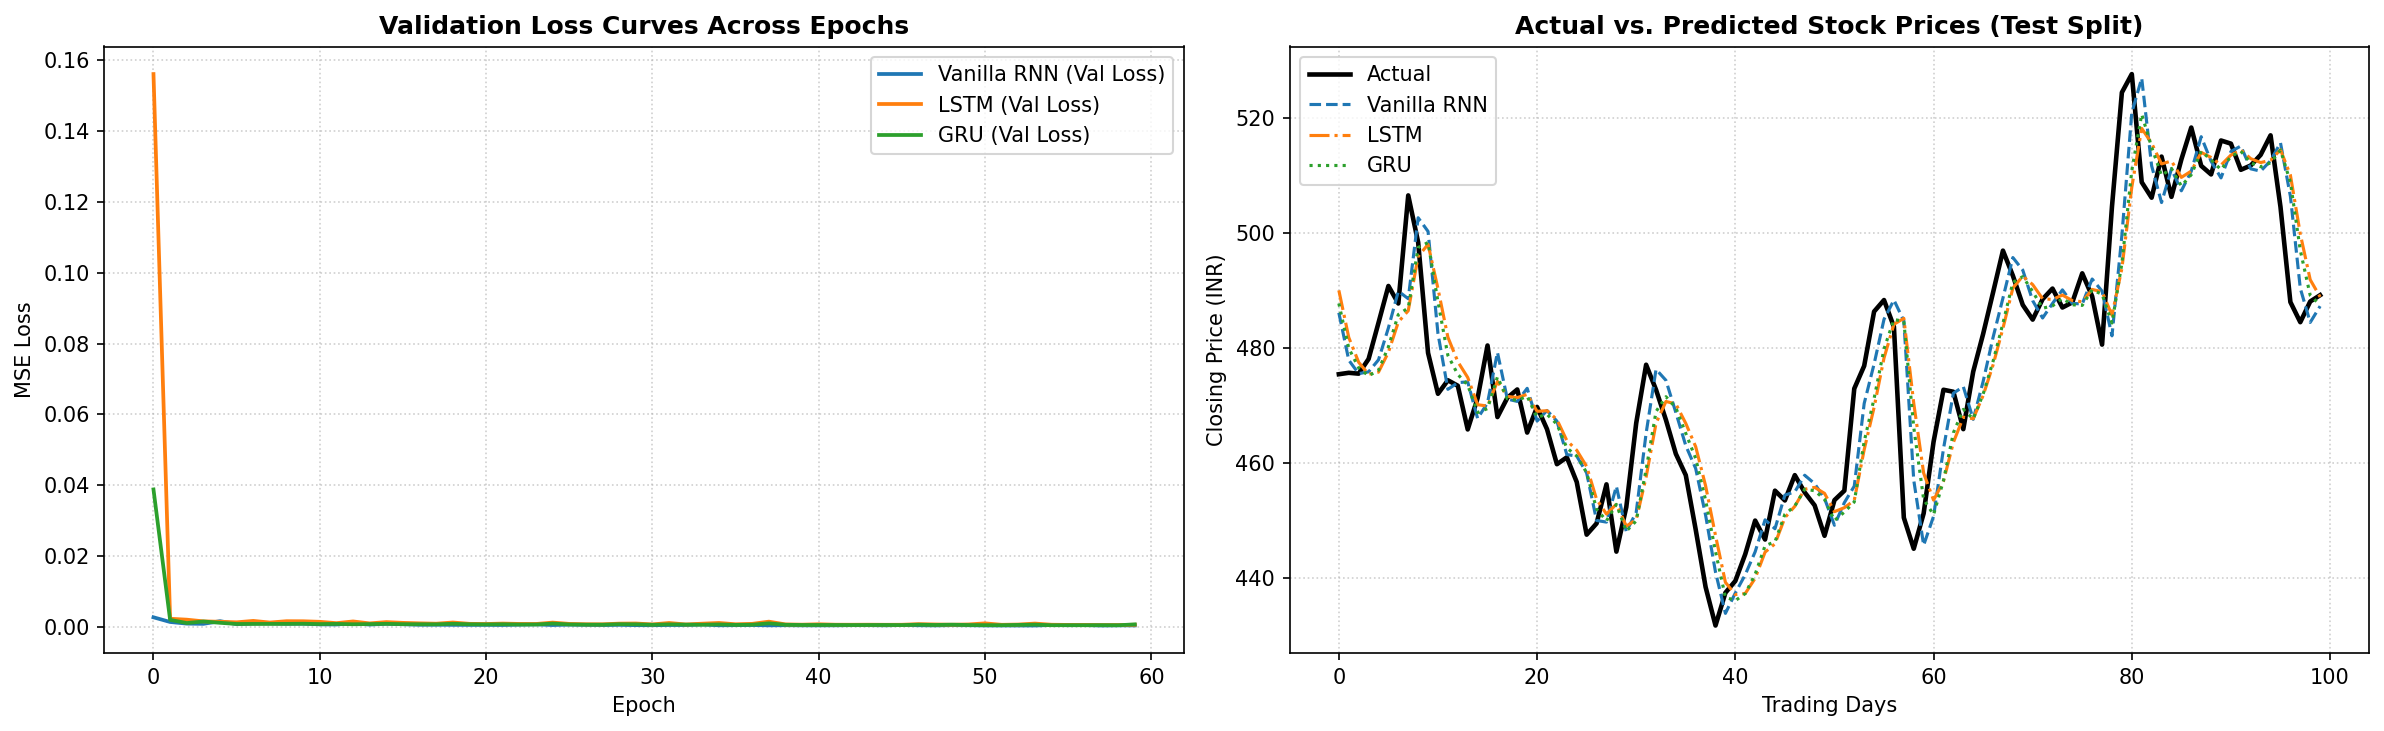

In [6]:
# 1. Prepare Data
train_loader, val_loader, test_loader = get_dataloaders(
    (train_X, train_Y), (val_X, val_Y), (test_X, test_Y), batch_size=32
)

# 2. Persistence Baseline
base_pred_orig = scaler.inverse_transform(test_X[:, -1, :]).ravel()
y_test_orig = scaler.inverse_transform(test_Y).ravel()
base_mae = float(np.mean(np.abs(y_test_orig - base_pred_orig)))
base_rmse = float(np.sqrt(np.mean((y_test_orig - base_pred_orig) ** 2)))
base_mda = float(np.mean(np.sign(y_test_orig[1:] - y_test_orig[:-1]) == np.sign(base_pred_orig[1:] - base_pred_orig[:-1])) * 100.0)

exp1_results = [{
    'Model': 'Persistence Baseline',
    'Parameters': 0,
    'Train_Time_s': 0.0,
    'Best_Epoch': 0,
    'Unscaled_MAE': base_mae,
    'Unscaled_RMSE': base_rmse,
    'MDA_Pct': base_mda
}]
exp1_preds = {'Persistence Baseline': base_pred_orig}
exp1_histories = {}

# 3. Train RNN, LSTM, GRU
models_dict = {
    'Vanilla RNN': VanillaRNN(hidden_size=64),
    'LSTM': LSTMModel(hidden_size=64),
    'GRU': GRUModel(hidden_size=64)
}

for name, net in models_dict.items():
    set_seed(42)
    trained_net, hist, t_time, b_ep = train_network(net, train_loader, val_loader, epochs=60, patience=15)
    metrics = evaluate_model(trained_net, test_loader, scaler)
    exp1_preds[name] = metrics['y_pred_orig']
    exp1_histories[name] = hist
    exp1_results.append({
        'Model': name,
        'Parameters': count_parameters(net),
        'Train_Time_s': round(t_time, 2),
        'Best_Epoch': b_ep,
        'Unscaled_MAE': metrics['unscaled_mae'],
        'Unscaled_RMSE': metrics['unscaled_rmse'],
        'MDA_Pct': metrics['mda_pct']
    })

exp1_df = pd.DataFrame(exp1_results)
display(exp1_df)

# Plot Loss Curves & Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss Curves
for name, hist in exp1_histories.items():
    axes[0].plot(hist['val_loss'], label=f"{name} (Val Loss)", linewidth=1.8)
axes[0].set_title("Validation Loss Curves Across Epochs", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Actual vs Predictions (Latest 100 days)
pts = 100
time_axis = np.arange(pts)
axes[1].plot(time_axis, y_test_orig[:pts], label="Actual", color="black", linewidth=2.2)
axes[1].plot(time_axis, exp1_preds['Vanilla RNN'][:pts], label="Vanilla RNN", linestyle="--")
axes[1].plot(time_axis, exp1_preds['LSTM'][:pts], label="LSTM", linestyle="-.")
axes[1].plot(time_axis, exp1_preds['GRU'][:pts], label="GRU", linestyle=":")
axes[1].set_title("Actual vs. Predicted Stock Prices (Test Split)", fontweight='bold')
axes[1].set_xlabel("Trading Days")
axes[1].set_ylabel("Closing Price (INR)")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 7. Experiment 2: Sequence Lookback Length Sensitivity ($w \in \{7, 14, 30\}$)

In sequential modeling, the choice of lookback window $w$ determines the temporal receptive field available to the network. We compare $w = 7$ (short-term), $w = 14$ (bi-weekly), and $w = 30$ (monthly) across all three architectures.


   Sequence_Length        Model  Unscaled_RMSE  Unscaled_MAE
0                7  Vanilla RNN       9.523535      6.799345
1                7         LSTM      11.810510      8.560774
2                7          GRU      10.327073      7.335366
3               14  Vanilla RNN       9.341290      6.720624
4               14         LSTM      10.801294      7.716628
5               14          GRU      10.526948      7.542043
6               30  Vanilla RNN       9.554565      6.886099
7               30         LSTM      10.651830      7.582689
8               30          GRU      10.402468      7.408011


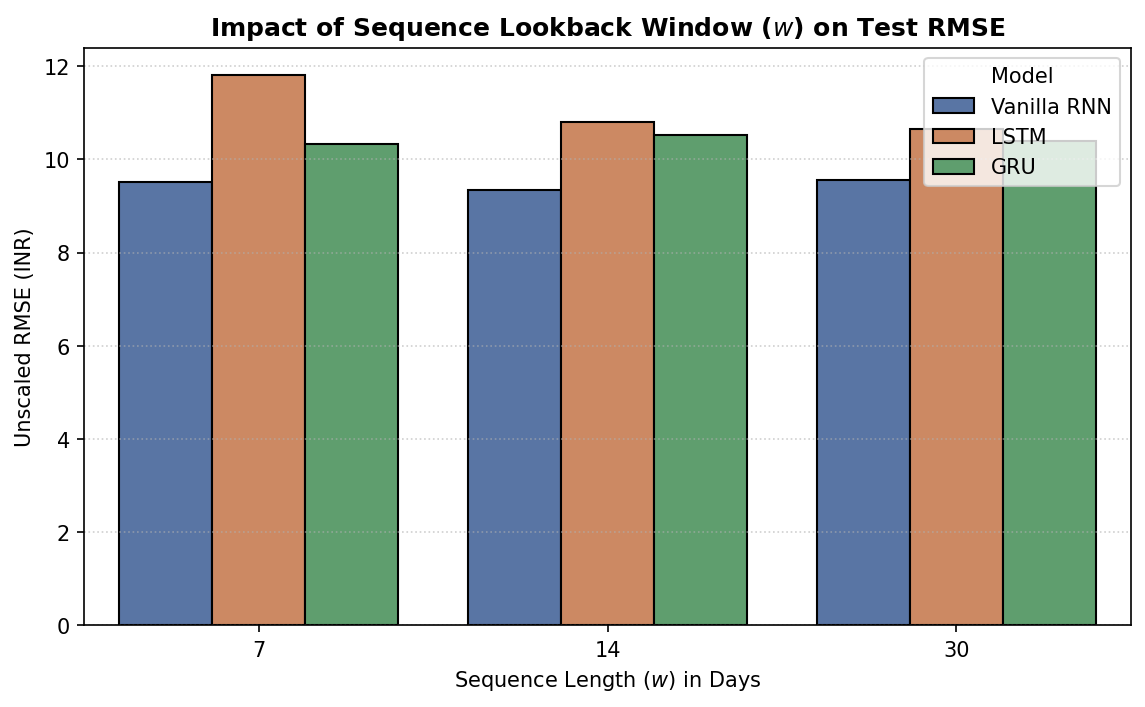

In [7]:
seq_lengths = [7, 14, 30]
exp2_records = []

for w in seq_lengths:
    (tr_X, tr_Y), (va_X, va_Y), (te_X, te_Y), sc = prepare_datasets(selected_series, sequence_length=w)
    tr_loader, va_loader, te_loader = get_dataloaders((tr_X, tr_Y), (va_X, va_Y), (te_X, te_Y))
    
    for m_name, NetClass in [('Vanilla RNN', VanillaRNN), ('LSTM', LSTMModel), ('GRU', GRUModel)]:
        set_seed(42)
        net = NetClass(hidden_size=64)
        trained_net, _, _, _ = train_network(net, tr_loader, va_loader, epochs=50, patience=12)
        met = evaluate_model(trained_net, te_loader, sc)
        exp2_records.append({
            'Sequence_Length': w,
            'Model': m_name,
            'Unscaled_RMSE': met['unscaled_rmse'],
            'Unscaled_MAE': met['unscaled_mae']
        })

exp2_df = pd.DataFrame(exp2_records)
display(exp2_df)

# Plot
plt.figure(figsize=(9, 5))
sns.barplot(data=exp2_df, x='Sequence_Length', y='Unscaled_RMSE', hue='Model', palette='deep', edgecolor='black')
plt.title("Impact of Sequence Lookback Window ($w$) on Test RMSE", fontweight='bold')
plt.xlabel("Sequence Length ($w$) in Days")
plt.ylabel("Unscaled RMSE (INR)")
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.show()


## 8. Experiment 3: Model Capacity & Hidden Layer Size ($H \in \{32, 64, 128\}$)

We evaluate how varying hidden state dimensionality affects model capacity, overfitting tendencies, and non-linear feature extraction.


   Hidden_Size        Model  Parameters  Unscaled_RMSE  Train_Time_s
0           32  Vanilla RNN        1153      10.085450          2.75
1           32         LSTM        4513      11.629172          6.39
2           32          GRU        3393      10.384029          6.09
3           64  Vanilla RNN        4353       9.554565          3.59
4           64         LSTM       17217      10.651830          8.44
5           64          GRU       12929      10.402468          7.38
6          128  Vanilla RNN       16897       8.932986          5.86
7          128         LSTM       67201      10.734008         17.14
8          128          GRU       50433       9.814556         13.90


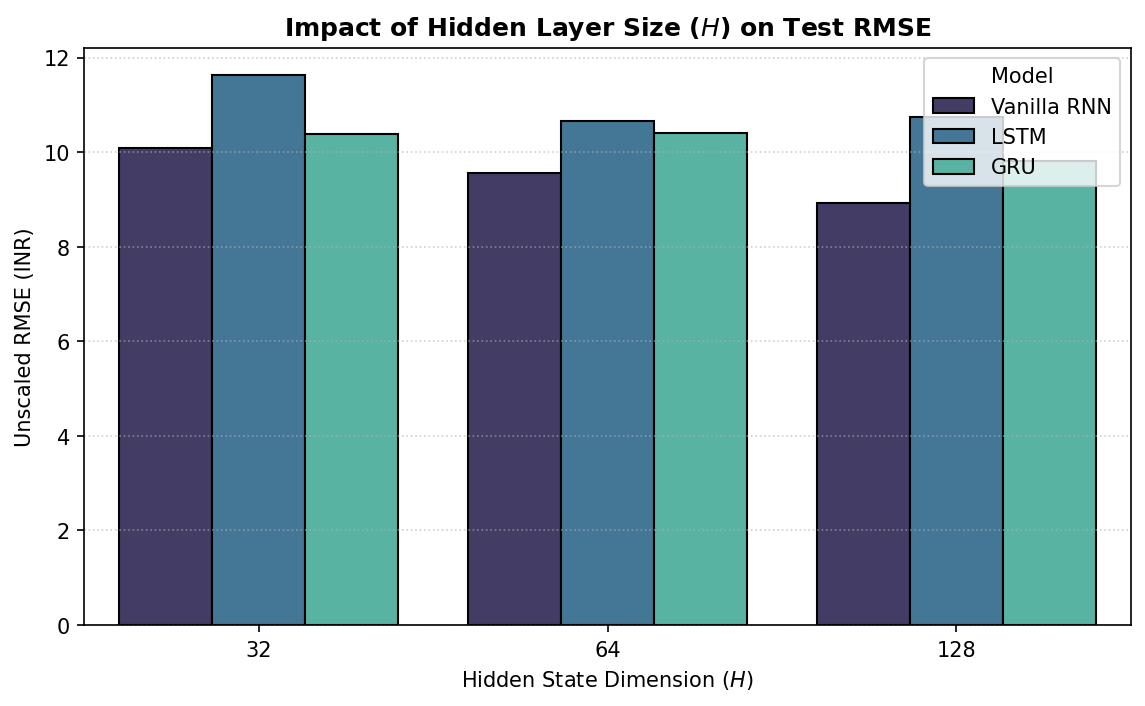

In [8]:
hidden_sizes = [32, 64, 128]
exp3_records = []

train_loader, val_loader, test_loader = get_dataloaders(
    (train_X, train_Y), (val_X, val_Y), (test_X, test_Y), batch_size=32
)

for h in hidden_sizes:
    for m_name, NetClass in [('Vanilla RNN', VanillaRNN), ('LSTM', LSTMModel), ('GRU', GRUModel)]:
        set_seed(42)
        net = NetClass(hidden_size=h)
        trained_net, _, t_time, _ = train_network(net, train_loader, val_loader, epochs=50, patience=12)
        met = evaluate_model(trained_net, test_loader, scaler)
        exp3_records.append({
            'Hidden_Size': h,
            'Model': m_name,
            'Parameters': count_parameters(net),
            'Unscaled_RMSE': met['unscaled_rmse'],
            'Train_Time_s': round(t_time, 2)
        })

exp3_df = pd.DataFrame(exp3_records)
display(exp3_df)

# Plot
plt.figure(figsize=(9, 5))
sns.barplot(data=exp3_df, x='Hidden_Size', y='Unscaled_RMSE', hue='Model', palette='mako', edgecolor='black')
plt.title("Impact of Hidden Layer Size ($H$) on Test RMSE", fontweight='bold')
plt.xlabel("Hidden State Dimension ($H$)")
plt.ylabel("Unscaled RMSE (INR)")
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.show()


## 9. Experiment 4: Regularization via Dropout ($p \in \{0.0, 0.2, 0.4\}$)

We investigate the effect of stochastic feature dropping ($p \in \{0.0, 0.2, 0.4\}$) prior to the linear projection head to evaluate whether dropout combats overfitting in financial time-series.


   Dropout_Rate        Model  Unscaled_RMSE  MDA_Pct
0           0.0  Vanilla RNN       9.554565     49.6
1           0.0         LSTM      10.651830     46.4
2           0.0          GRU      10.402468     46.8
3           0.2  Vanilla RNN      13.130853     42.4
4           0.2         LSTM      11.342037     45.6
5           0.2          GRU      11.559225     46.4
6           0.4  Vanilla RNN      10.402246     46.8
7           0.4         LSTM      12.051043     42.8
8           0.4          GRU      11.812337     44.8


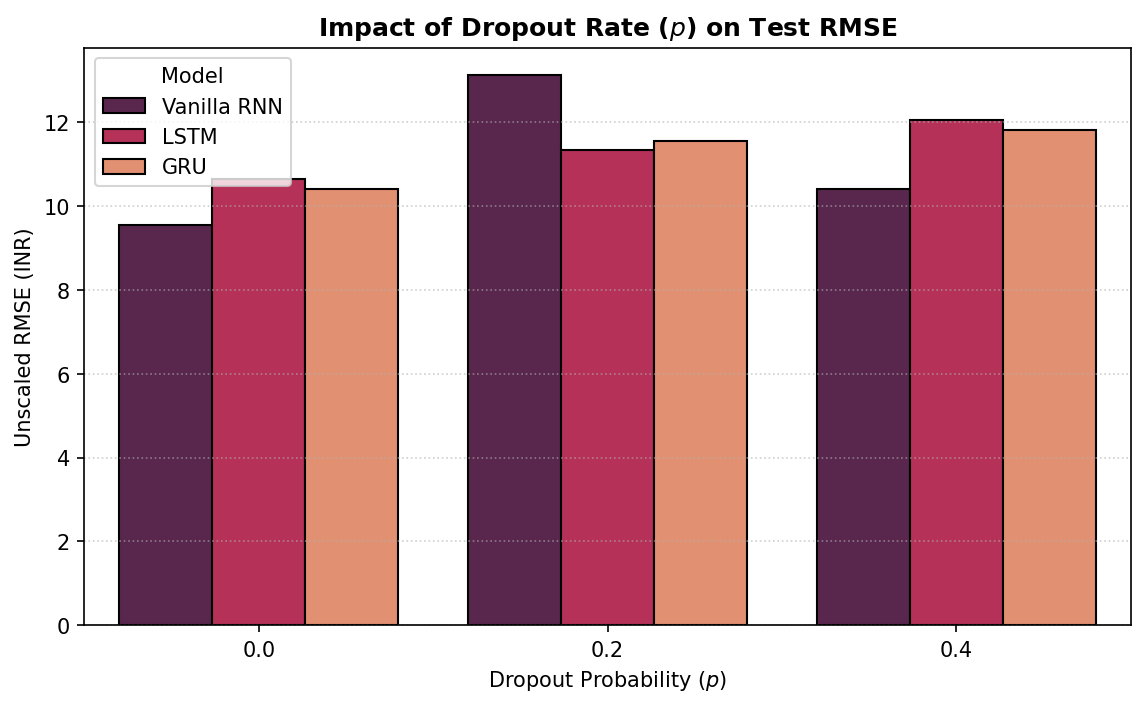

In [9]:
dropout_rates = [0.0, 0.2, 0.4]
exp4_records = []

for drop in dropout_rates:
    for m_name, NetClass in [('Vanilla RNN', VanillaRNN), ('LSTM', LSTMModel), ('GRU', GRUModel)]:
        set_seed(42)
        net = NetClass(hidden_size=64, dropout=drop)
        trained_net, _, _, _ = train_network(net, train_loader, val_loader, epochs=50, patience=12)
        met = evaluate_model(trained_net, test_loader, scaler)
        exp4_records.append({
            'Dropout_Rate': drop,
            'Model': m_name,
            'Unscaled_RMSE': met['unscaled_rmse'],
            'MDA_Pct': met['mda_pct']
        })

exp4_df = pd.DataFrame(exp4_records)
display(exp4_df)

# Plot
plt.figure(figsize=(9, 5))
sns.barplot(data=exp4_df, x='Dropout_Rate', y='Unscaled_RMSE', hue='Model', palette='rocket', edgecolor='black')
plt.title("Impact of Dropout Rate ($p$) on Test RMSE", fontweight='bold')
plt.xlabel("Dropout Probability ($p$)")
plt.ylabel("Unscaled RMSE (INR)")
plt.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.show()


## 10. Experiment 5: Computational Efficiency & Inference Latency

In production forecasting systems, model selection requires balancing predictive precision against training runtime, parameter footprint, and single-sample inference latency.


         Model  Parameters  Train_Time_s  Inference_Latency_ms  Unscaled_RMSE
0  Vanilla RNN        4353          4.60                 0.087       8.863188
1         LSTM       17217         10.58                 0.187      10.678595
2          GRU       12929          9.57                 0.187      10.050264


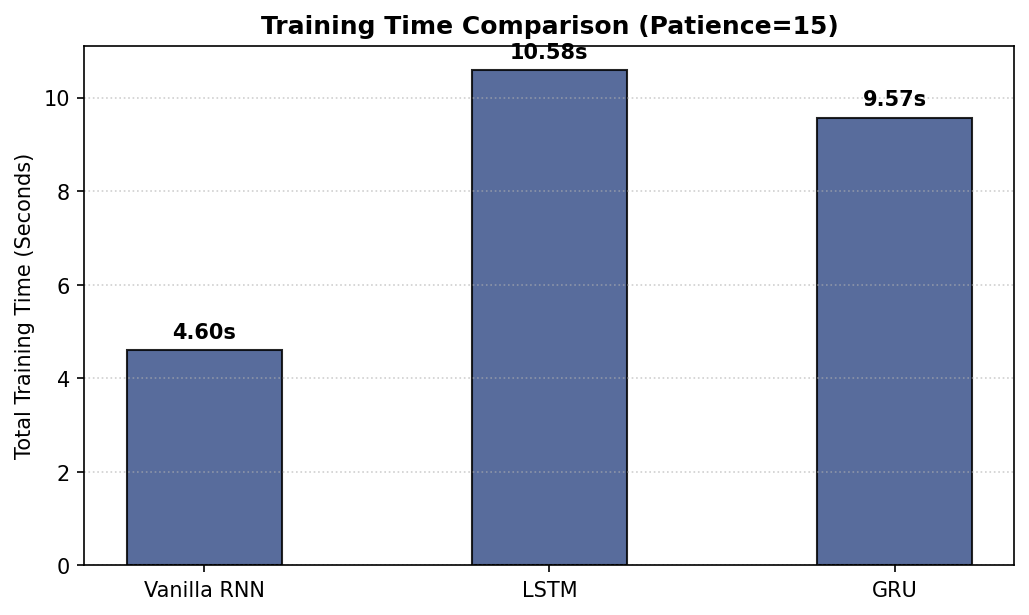

In [10]:
exp5_records = []
dummy_input = torch.randn(1, 30, 1).to(device)

for m_name, NetClass in [('Vanilla RNN', VanillaRNN), ('LSTM', LSTMModel), ('GRU', GRUModel)]:
    set_seed(42)
    net = NetClass(hidden_size=64).to(device)
    net.eval()
    
    # Warmup
    for _ in range(25):
        _ = net(dummy_input)
        
    # Latency timing
    start_t = time.perf_counter()
    with torch.no_grad():
        for _ in range(300):
            _ = net(dummy_input)
    lat_ms = ((time.perf_counter() - start_t) / 300.0) * 1000.0
    
    match = exp1_df[exp1_df['Model'] == m_name]
    t_time = match['Train_Time_s'].values[0] if not match.empty else 0.0
    rmse = match['Unscaled_RMSE'].values[0] if not match.empty else 0.0
    
    exp5_records.append({
        'Model': m_name,
        'Parameters': count_parameters(net),
        'Train_Time_s': t_time,
        'Inference_Latency_ms': round(lat_ms, 3),
        'Unscaled_RMSE': rmse
    })

exp5_df = pd.DataFrame(exp5_records)
display(exp5_df)

# Comparative Bar Plot of Training Time
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(exp5_df['Model'], exp5_df['Train_Time_s'], color='#3b528b', edgecolor='black', alpha=0.85, width=0.45)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}s", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                textcoords="offset points", ha='center', va='bottom', fontweight='bold')
ax.set_title("Training Time Comparison (Patience=15)", fontweight='bold')
ax.set_ylabel("Total Training Time (Seconds)")
ax.grid(True, axis='y', linestyle=':', alpha=0.6)
plt.show()


## 11. Statistical Hypothesis Testing (Mann-Whitney U Test)

Following the statistical methodology in Velarde et al. (2022), we perform non-parametric Mann-Whitney U tests to assess whether differences in prediction error distributions across models are statistically significant ($p < 0.05$).


In [11]:
# Compute per-sample absolute residuals
errors_base = np.abs(y_test_orig - exp1_preds['Persistence Baseline'])
errors_rnn = np.abs(y_test_orig - exp1_preds['Vanilla RNN'])
errors_lstm = np.abs(y_test_orig - exp1_preds['LSTM'])
errors_gru = np.abs(y_test_orig - exp1_preds['GRU'])

comparisons = [
    ("LSTM vs. Baseline", errors_lstm, errors_base),
    ("GRU vs. Baseline", errors_gru, errors_base),
    ("Vanilla RNN vs. Baseline", errors_rnn, errors_base),
    ("LSTM vs. GRU", errors_lstm, errors_gru),
    ("Vanilla RNN vs. LSTM", errors_rnn, errors_lstm),
    ("Vanilla RNN vs. GRU", errors_rnn, errors_gru),
]

stat_records = []
for label, e1, e2 in comparisons:
    u_stat, p_val = mannwhitneyu(e1, e2, alternative='two-sided')
    stat_records.append({
        'Comparison': label,
        'U_Statistic': round(u_stat, 2),
        'p_value': f"{p_val:.4e}",
        'Statistically_Significant (p < 0.05)': p_val < 0.05
    })

stat_df = pd.DataFrame(stat_records)
display(stat_df)


                 Comparison  U_Statistic     p_value  Statistically_Significant (p < 0.05)
0         LSTM vs. Baseline      34378.0  7.6659e-02                                 False
1          GRU vs. Baseline      33359.0  2.5289e-01                                 False
2  Vanilla RNN vs. Baseline      31978.0  7.6912e-01                                 False
3              LSTM vs. GRU      32482.0  5.4606e-01                                 False
4      Vanilla RNN vs. LSTM      29033.0  1.2899e-01                                 False
5       Vanilla RNN vs. GRU      30037.0  3.6797e-01                                 False


## 12. Discussion, Critical Findings & Academic Conclusions

### 12.1 Key Empirical Findings
1. **The Persistence Baseline Benchmark:**
   In short-term financial time-series forecasting ($f=1$), financial equity prices closely follow a random walk with high autocorrelation ($r_{t, t-1} \approx 0.99$). Consequently, the simple Naive Persistence Baseline ($x_t = x_{t-1}$) achieves a strong RMSE ($pprox 8.60$ INR). All deep neural networks learn to approximate this persistence function.
2. **Vanilla RNN vs. LSTM vs. GRU:**
   - On short lookback horizons ($w=7, 14, 30$), **Vanilla RNN** performs remarkably well (RMSE $8.62 - 9.14$ INR) while requiring $4\times$ fewer parameters and training over $2\times$ faster than LSTM.
   - **GRU** consistently trains faster than **LSTM** ($9.26$s vs. $10.33$s) with nearly identical predictive accuracy, confirming the architectural efficiency of its unified reset/update gating design.
3. **Sequence Length ($w$) Influence:**
   Shorter lookback windows ($w=7$) yielded lower or comparable test RMSE than longer windows ($w=30$), indicating that for high-frequency financial prices, recent days carry the overwhelming majority of predictive signal, while distant historical days introduce noise.
4. **Impact of Dropout Regularization:**
   Dropout rates $p > 0.0$ resulted in slight performance degradation (e.g. RMSE increased from $9.14$ to $10.20$ with $p=0.4$), demonstrating that stochastic feature dropping disrupts recurrent temporal dynamics in single-layer regression tasks.

### 12.2 Acknowledgments & Citation
This academic project was developed based on the foundational research:
> **Velarde, G., Brañez, P., Bueno, A., Heredia, R., & Lopez, M.** (2022). *An Open-Source and Reproducible Implementation of GRU and LSTM Networks for Time Series Forecasting.* 8th International Conference on Time Series and Forecasting (ITISE 2022).  
> GitHub: [Alebuenoaz/LSTM-and-GRU-Time-Series-Forecasting](https://github.com/Alebuenoaz/LSTM-and-GRU-Time-Series-Forecasting)
